# Crimes Sexuais no Ceará (2009–2025): análise exploratória, temporal, geográfica e estatística

**Objetivo:** entender o perfil das vítimas, a evolução no tempo e a distribuição territorial dos registros de crimes sexuais no Ceará, e testar estatisticamente os padrões encontrados.

**Perguntas de negócio**
1. Quem são as vítimas (gênero, idade, raça, escolaridade)?
2. Como os registros evoluíram entre 2009 e 2025? Há tendência, sazonalidade, efeito da pandemia?
3. Em quais dias da semana e horários os crimes são registrados?
4. Onde se concentram (município / AIS)?
5. Os padrões observados são estatisticamente significativos?

**Aviso importante:** os dados são *registros* policiais, não a incidência real. Crimes sexuais têm alta subnotificação, e variações podem refletir mudanças de denúncia/registro, não só de ocorrência.

**Stack:** Python, pandas, matplotlib, seaborn, scipy.

## 1. Setup e carga dos dados

In [6]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook', palette='deep')
plt.rcParams.update({'figure.dpi':110,'axes.titleweight':'bold','axes.titlesize':13})
ARQUIVO = '../data/processed/Crimes-Sexuais_2009-a-2025_com_regiao.xlsx'   # ajuste o caminho se necessário
df_raw = pd.read_excel(ARQUIVO, sheet_name='Sheet1')
df = df_raw.copy()
print(df.shape)
df.head()

(30772, 10)


,AIS,Município,Região,Data,Hora,Dia da Semana,Gênero,Idade da Vítima,Escolaridade da Vítima,Raça da Vítima
0,AIS 25,Itaitinga,Grande Fortaleza,2009-01-01,01:30:00,Quinta,Feminino,13,Não Informada,Não Informada
1,AIS 30,Aracati,Litoral Leste,2009-01-01,20:30:00,Quinta,Feminino,41,Não Informada,Não Informada
2,AIS 06,Fortaleza,Grande Fortaleza,2009-01-02,11:06:06,Sexta,Masculino,16,Não Informada,Não Informada
3,AIS Não Identificada (Caucaia),Caucaia,Grande Fortaleza,2009-01-02,12:13:09,Sexta,Feminino,13,Não Informada,Não Informada
4,AIS 20,Fortaleza,Grande Fortaleza,2009-01-02,21:04:52,Sexta,Feminino,13,Não Informada,Não Informada


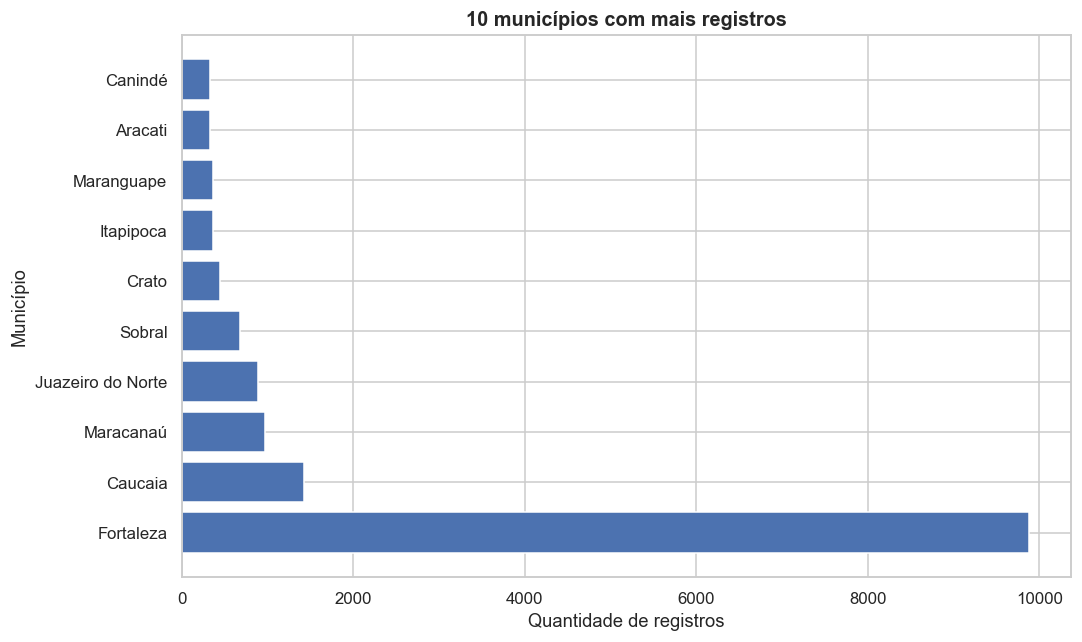

In [7]:
quantidade = df['Município'].value_counts().head(10)
plt.figure(figsize=(10, 6))

plt.barh(
    quantidade.index,
    quantidade.values
)

plt.title('10 municípios com mais registros')
plt.xlabel('Quantidade de registros')
plt.ylabel('Município')

plt.tight_layout()
plt.show()

## 2. Qualidade dos dados

In [3]:
df.info()
print('\nDuplicatas exatas:', df.duplicated().sum())
print('Período:', df['Data'].min().date(), 'a', df['Data'].max().date())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30772 entries, 0 to 30771
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   AIS                     30772 non-null  object        
 1   Município               30772 non-null  object        
 2   Data                    30772 non-null  datetime64[ns]
 3   Hora                    30772 non-null  object        
 4   Dia da Semana           30772 non-null  object        
 5   Gênero                  30772 non-null  object        
 6   Idade da Vítima         30772 non-null  object        
 7   Escolaridade da Vítima  30772 non-null  object        
 8   Raça da Vítima          30772 non-null  object        
dtypes: datetime64[ns](1), object(8)
memory usage: 2.1+ MB

Duplicatas exatas: 347
Período: 2009-01-01 a 2025-12-31


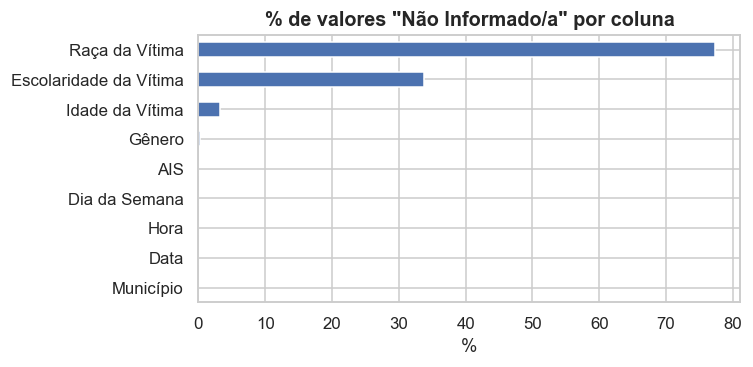

In [4]:
# Proporção de 'Não Informad*' em cada coluna
nao_inf = df.apply(lambda s: s.astype(str).str.startswith('Não Informad').mean()).sort_values(ascending=False)
ax = (nao_inf*100).plot.barh(figsize=(7,3.5), color='#4C72B0')
ax.set_title('% de valores "Não Informado/a" por coluna'); ax.set_xlabel('%')
ax.invert_yaxis(); plt.tight_layout(); plt.show()

In [5]:
# Ordenar da menor para a maior quantidade
valores_ausentes = valores_ausentes.sort_values()

# Criar a figura e o eixo
fig, ax = plt.subplots(figsize=(10, 6))

# Criar as barras horizontais
barras = ax.barh(
    valores_ausentes.index,
    valores_ausentes.values,
    color=sns.color_palette('deep', len(valores_ausentes))
)

# Adicionar os valores nas barras
ax.bar_label(
    barras,
    fmt='{:,.0f}',
    label_type='edge',
    padding=5
)

# Personalizar o gráfico
ax.set_title('Quantidade de valores não informados por coluna')
ax.set_xlabel('Quantidade de registros não informados')
ax.set_ylabel('Colunas')

# Dar espaço para os números
ax.set_xlim(0, max(valores_ausentes.max() * 1.15, 1))

# Ajustar o layout
plt.tight_layout()

# Exibir o gráfico
plt.show()

NameError: name 'valores_ausentes' is not defined

**Achados de qualidade**
- Não há nulos, mas a ausência vem codificada como `Não Informado/a`: é alta em **Raça** e **Escolaridade** (analisar essas variáveis exige cautela).
- Existem registros duplicados exatos. Sem um ID de ocorrência, **não dá para afirmar** que são erros (podem ser vítimas distintas no mesmo caso/horário). Decisão: **manter**, e reportar sensibilidade removendo-os.
- A coluna `Hora` tem forte concentração em horas cheias (ex.: 10:00), sugerindo horário *aproximado/declarado* e não preciso.

## 3. Limpeza e engenharia de atributos

In [6]:
df.columns = ['ais','municipio','data','hora','dia_semana','genero','idade','escolaridade','raca']
for c in ['municipio','ais','genero','escolaridade','raca','dia_semana']:
    df[c] = df[c].astype(str).str.strip()

# Idade numérica; 'Não Informada' -> NaN
df['idade'] = pd.to_numeric(df['idade'], errors='coerce')

# Tempo
df['ano']  = df['data'].dt.year
df['mes']  = df['data'].dt.month
df['hora_int'] = pd.to_datetime(df['hora'], format='%H:%M:%S', errors='coerce').dt.hour
ordem_dias = ['Segunda','Terça','Quarta','Quinta','Sexta','Sábado','Domingo']
df['dia_semana'] = pd.Categorical(df['dia_semana'], ordem_dias, ordered=True)
df['periodo'] = pd.cut(df['hora_int'], [-1,5,11,17,23], labels=['Madrugada','Manhã','Tarde','Noite'])

# Faixa etária (marcos legais: <14 = estupro de vulnerável)
df['faixa_etaria'] = pd.cut(df['idade'], [-1,11,13,17,29,59,120],
    labels=['0-11 (criança)','12-13','14-17 (adolescente)','18-29','30-59','60+'])

# Genéricos para "Não Informad*" -> NaN nas colunas analíticas
for c in ['raca','escolaridade','genero']:
    df[c+'_ok'] = df[c].where(~df[c].str.startswith('Não Informad'))

# Localização
df['capital'] = np.where(df['municipio']=='Fortaleza','Fortaleza','Interior/RMF')
df['ais_ident'] = ~df['ais'].str.contains('Não Identificada')
print('Idade ausente:', df['idade'].isna().sum(), f"({df['idade'].isna().mean():.1%})")
df[['data','ano','hora_int','periodo','idade','faixa_etaria']].head()

Idade ausente: 1015 (3.3%)


,data,ano,hora_int,periodo,idade,faixa_etaria
0,2009-01-01,2009,1,Madrugada,13.0,12-13
1,2009-01-01,2009,20,Noite,41.0,30-59
2,2009-01-02,2009,11,Manhã,16.0,14-17 (adolescente)
3,2009-01-02,2009,12,Tarde,13.0,12-13
4,2009-01-02,2009,21,Noite,13.0,12-13


## 4. Perfil das vítimas

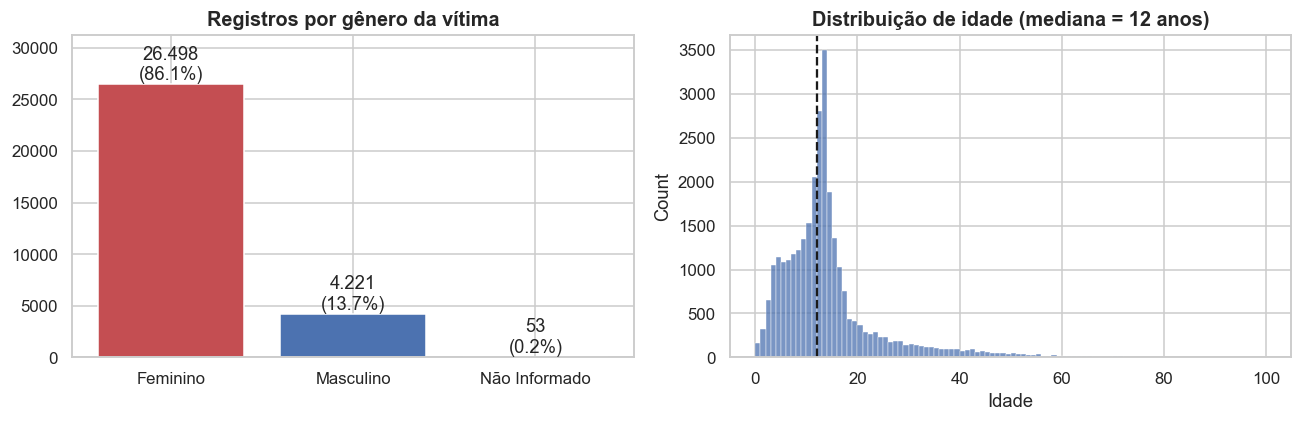

In [7]:
fig, axes = plt.subplots(1,2, figsize=(12,4))
g = df['genero'].value_counts()
axes[0].bar(g.index, g.values, color=['#C44E52','#4C72B0','#999999'])
for i,v in enumerate(g.values): axes[0].text(i, v, f'{v:,}\n({v/len(df):.1%})'.replace(',','.'), ha='center', va='bottom')
axes[0].set_title('Registros por gênero da vítima'); axes[0].set_ylim(0, g.max()*1.18)

sns.histplot(df['idade'].dropna(), bins=np.arange(0,101,1), ax=axes[1], color='#4C72B0')
axes[1].axvline(df['idade'].median(), color='k', ls='--'); 
axes[1].set_title(f"Distribuição de idade (mediana = {df['idade'].median():.0f} anos)")
axes[1].set_xlabel('Idade'); plt.tight_layout(); plt.show()

             count  mean   std  min  25%   50%   75%    max
genero                                                     
Feminino   25684.0  14.4  10.7  0.0  9.0  12.0  16.0  100.0
Masculino   4073.0  11.4   9.7  0.0  6.0   9.0  13.0   91.0

% vítimas com <14 anos (entre idade informada): 64.4%
% vítimas com <18 anos: 81.3%


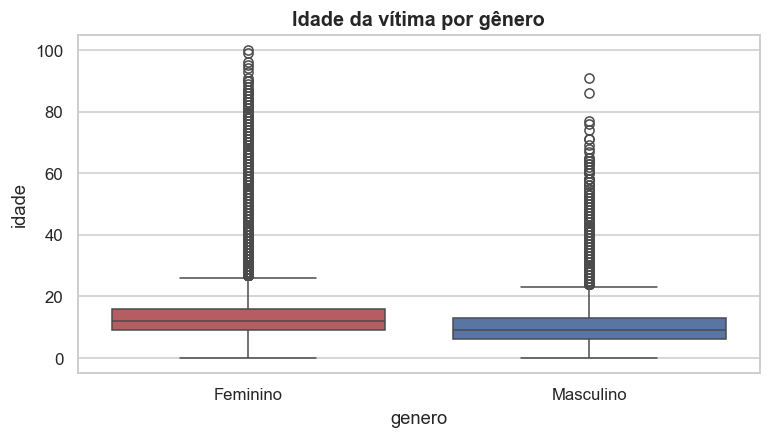

In [8]:
# Idade por gênero e % de menores
df_g = df[df['genero_ok'].notna()]
print(df_g.groupby('genero')['idade'].describe().round(1))
print('\n% vítimas com <14 anos (entre idade informada):', f"{(df['idade']<14).sum()/df['idade'].notna().sum():.1%}")
print('% vítimas com <18 anos:', f"{(df['idade']<18).sum()/df['idade'].notna().sum():.1%}")

fig, ax = plt.subplots(figsize=(8,4))
sns.boxplot(data=df_g, x='genero', y='idade', ax=ax, palette=['#C44E52','#4C72B0'])
ax.set_title('Idade da vítima por gênero'); plt.show()

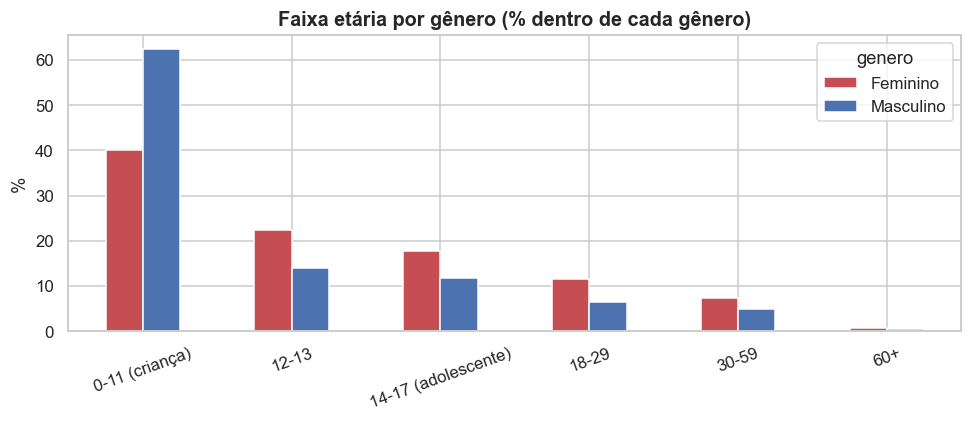

In [9]:
# Faixa etária x gênero (% dentro do gênero)
ct = pd.crosstab(df_g['faixa_etaria'], df_g['genero'], normalize='columns')*100
ax = ct.plot.bar(figsize=(9,4), color=['#C44E52','#4C72B0'], rot=20)
ax.set_title('Faixa etária por gênero (% dentro de cada gênero)'); ax.set_ylabel('%'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

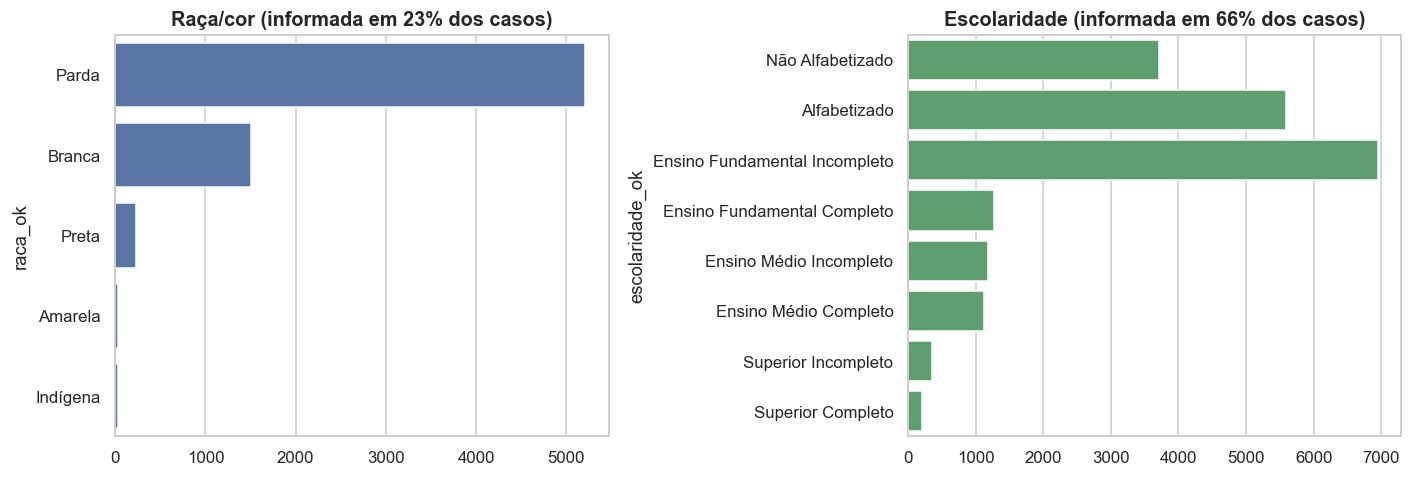

In [10]:
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
r = df['raca_ok'].value_counts()
sns.barplot(x=r.values, y=r.index, ax=axes[0], color='#4C72B0')
axes[0].set_title(f"Raça/cor (informada em {df['raca_ok'].notna().mean():.0%} dos casos)")
ordem_esc = ['Não Alfabetizado','Alfabetizado','Ensino Fundamental Incompleto','Ensino Fundamental Completo',
             'Ensino Médio Incompleto','Ensino Médio Completo','Superior Incompleto','Superior Completo']
e = df['escolaridade_ok'].value_counts().reindex(ordem_esc)
sns.barplot(x=e.values, y=e.index, ax=axes[1], color='#55A868')
axes[1].set_title(f"Escolaridade (informada em {df['escolaridade_ok'].notna().mean():.0%} dos casos)")
plt.tight_layout(); plt.show()

> **Leitura:** a escolaridade é fortemente influenciada pela idade (muitas vítimas são crianças em idade escolar). Comparar escolaridade sem controlar por idade leva a conclusões enganosas.
> Raça tem >75% de ausência; qualquer inferência é limitada ao subconjunto informado, que pode não ser representativo.

## 5. Análise temporal

In [ ]:
# Agrupar os crimes por Ano e calcular o total
tabela_anos = df['Ano'].value_counts().reset_index(name='Quantidade')
tabela_anos.columns = ['Ano', 'Quantidade']
tabela_anos = tabela_anos.sort_values('Ano').reset_index(drop=True)

# Calcular a variação percentual ano a ano
tabela_anos['Variação (%)'] = tabela_anos['Quantidade'].pct_change() * 100

print("=== Evolução Anual de Ocorrências (2009-2025) ===")
display(tabela_anos.style.format({
    'Quantidade': '{:,}',
    'Variação (%)': '{:+.2f}%'
}).hide(axis='index'))

# 2. Plotar gráfico de linha com a evolução temporal
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

grafico_anos = sns.lineplot(
    x='Ano',
    y='Quantidade',
    data=tabela_anos,
    marker='o',
    color='#2b5c8f',
    linewidth=2.5
)

# Adicionar os valores exatos em cada ponto do gráfico
for i in range(len(tabela_anos)):
    plt.text(
        tabela_anos['Ano'][i],
        tabela_anos['Quantidade'][i] + (tabela_anos['Quantidade'].max() * 0.02),
        f"{tabela_anos['Quantidade'][i]:,}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='#2b5c8f'
    )
plt.axvspan(2019.5, 2021.5, color='orange', alpha=.15, label='Pandemia (2020–21)')

plt.title('Evolução Histórica Anual de Crimes Sexuais Registrados (2009-2025)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Ano', fontsize=12)
plt.ylabel('Quantidade de Ocorrências', fontsize=12)
plt.xticks(tabela_anos['Ano'])
plt.ylim(0, tabela_anos['Quantidade'].max() * 1.12)

plt.tight_layout()
plt.show()

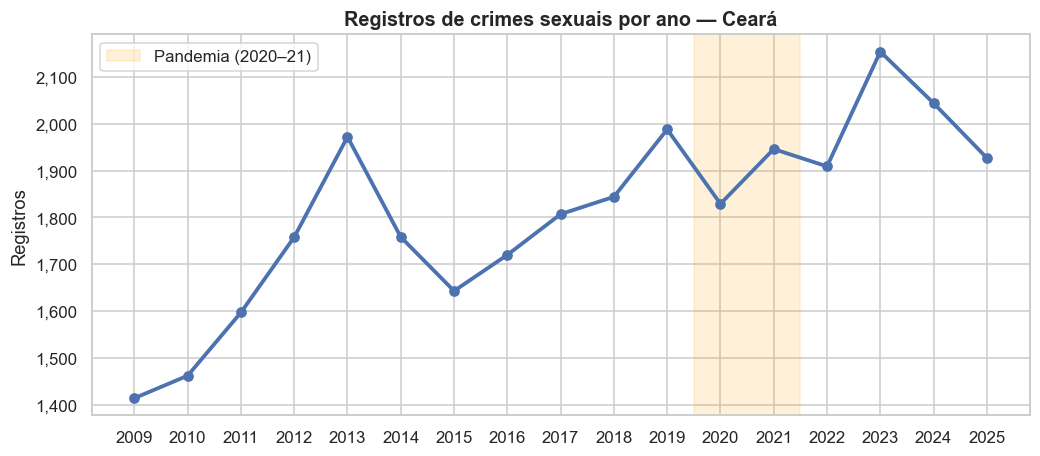

Variação 2009→2025: +36.3%  |  Pico: 2023 (2154 registros)


In [11]:
anual = df.groupby('ano').size()
fig, ax = plt.subplots(figsize=(11,4.5))
ax.plot(anual.index, anual.values, marker='o', lw=2.5, color='#4C72B0')
ax.axvspan(2019.5, 2021.5, color='orange', alpha=.15, label='Pandemia (2020–21)')
ax.set_title('Registros de crimes sexuais por ano — Ceará'); ax.set_ylabel('Registros')
ax.set_xticks(anual.index); ax.legend(); ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
plt.show()
cresc = (anual.loc[2025]/anual.loc[2009]-1)
print(f'Variação 2009→2025: {cresc:+.1%}  |  Pico: {anual.idxmax()} ({anual.max()} registros)')

In [12]:
# Tendência linear com teste de significância (Mann-Kendall simplificado via Kendall tau)
tau, p_tau = stats.kendalltau(anual.index, anual.values)
lr = stats.linregress(anual.index, anual.values)
print(f'Kendall tau = {tau:.2f} (p = {p_tau:.4f})')
print(f'Tendência linear: {lr.slope:+.1f} registros/ano (R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.4f})')

Kendall tau = 0.66 (p = 0.0002)
Tendência linear: +32.3 registros/ano (R² = 0.67, p = 0.0001)


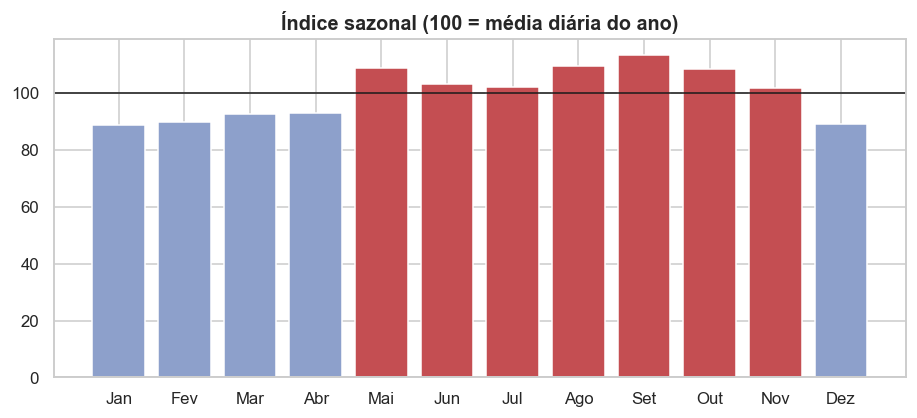

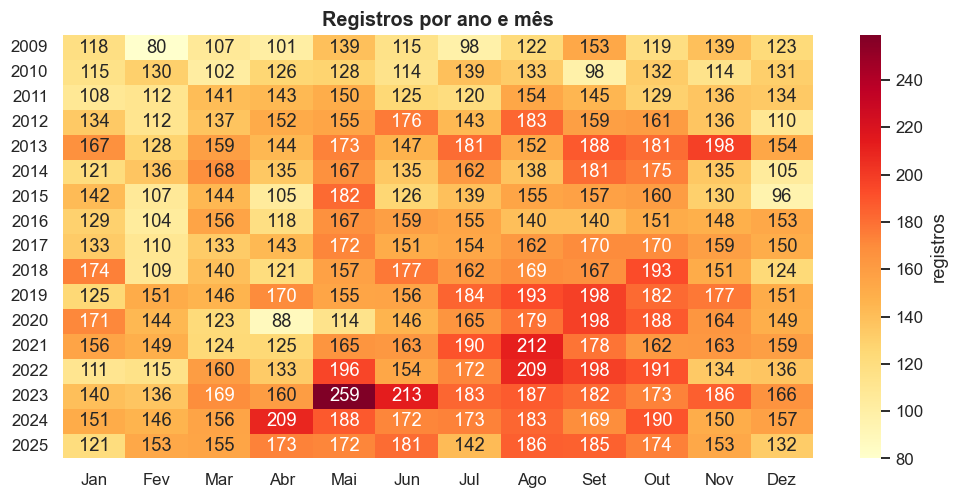

In [13]:
# Sazonalidade mensal (normalizada pelo nº de dias do mês para não favorecer meses longos)
m = df.groupby(['ano','mes']).size().unstack()
m = m.drop(index=[], errors='ignore')
dias = pd.Series({mm: pd.Period(f'2023-{mm:02d}').days_in_month for mm in range(1,13)})
media_dia = (m.mean()/dias)
indice = media_dia/media_dia.mean()*100
fig, ax = plt.subplots(figsize=(10,4))
nomes = ['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez']
ax.bar(nomes, indice.values, color=np.where(indice>=100,'#C44E52','#8da0cb'))
ax.axhline(100, color='k', lw=1); ax.set_title('Índice sazonal (100 = média diária do ano)')
plt.show()
plt.figure(figsize=(11,5))
sns.heatmap(m, cmap='YlOrRd', annot=True, fmt='.0f', cbar_kws={'label':'registros'}, xticklabels=nomes)
plt.title('Registros por ano e mês'); plt.ylabel(''); plt.xlabel(''); plt.show()

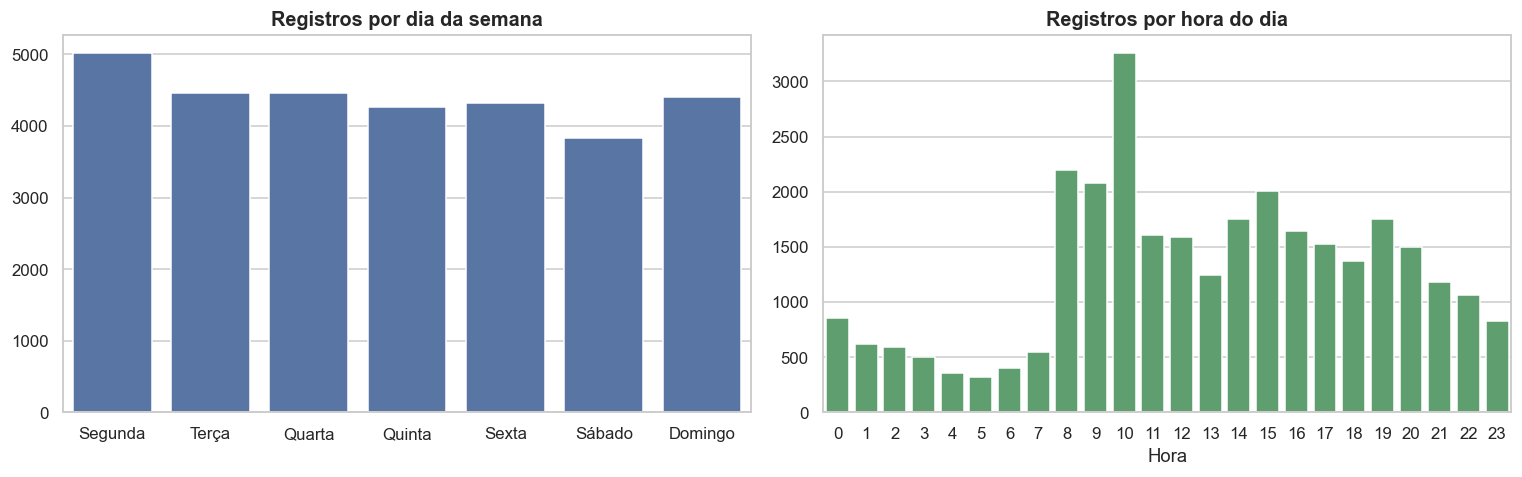

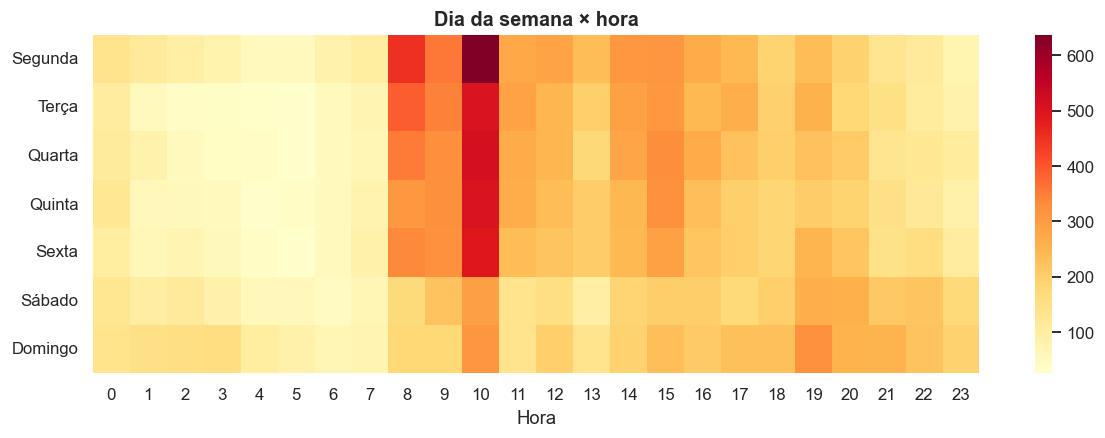

In [14]:
# Dia da semana e hora
fig, axes = plt.subplots(1,2, figsize=(14,4.5))
d = df['dia_semana'].value_counts().reindex(ordem_dias)
sns.barplot(x=d.index, y=d.values, ax=axes[0], color='#4C72B0'); axes[0].set_title('Registros por dia da semana'); axes[0].set_xlabel('')
h = df['hora_int'].value_counts().sort_index()
sns.barplot(x=h.index, y=h.values, ax=axes[1], color='#55A868'); axes[1].set_title('Registros por hora do dia'); axes[1].set_xlabel('Hora')
plt.tight_layout(); plt.show()

pt = pd.crosstab(df['dia_semana'], df['hora_int'])
plt.figure(figsize=(13,4)); sns.heatmap(pt, cmap='YlOrRd'); plt.title('Dia da semana × hora'); plt.xlabel('Hora'); plt.ylabel(''); plt.show()

In [15]:
# Horários em hora cheia (:00:00) → indício de horário aproximado
hc = (df['hora'].str.endswith(':00:00')).mean()
print(f'{hc:.1%} dos registros têm horário exatamente em hora cheia (esperado ao acaso: ~{1/3600:.2%}).')
# Horário por faixa etária
pt2 = pd.crosstab(df['faixa_etaria'], df['periodo'], normalize='index')*100
pt2.round(1)

55.3% dos registros têm horário exatamente em hora cheia (esperado ao acaso: ~0.03%).


periodo,Madrugada,Manhã,Tarde,Noite
faixa_etaria,,,,
0-11 (criança),5.3,34.1,35.5,25.1
12-13,8.3,36.4,31.4,23.9
14-17 (adolescente),11.4,33.5,31.4,23.7
18-29,25.4,24.7,23.6,26.3
30-59,24.1,23.2,23.3,29.4
60+,21.9,25.0,25.9,27.2


## 6. Análise geográfica

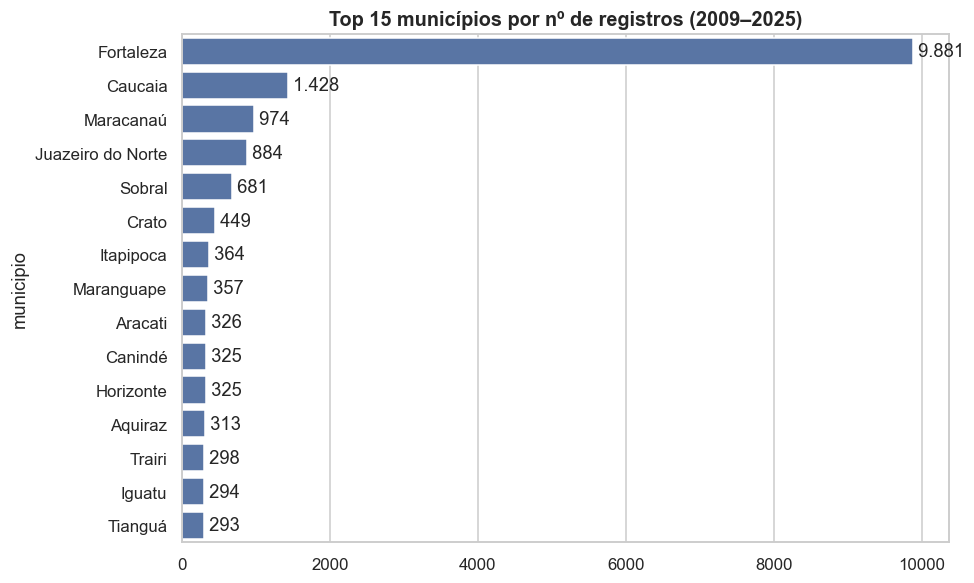

Fortaleza concentra 32.1% dos registros; 184 municípios no total.
Top 5 municípios = 45.0% do total.


In [16]:
top = df['municipio'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(9,6))
sns.barplot(x=top.values, y=top.index, color='#4C72B0', ax=ax)
for i,v in enumerate(top.values): ax.text(v, i, f' {v:,}'.replace(',','.'), va='center')
ax.set_title('Top 15 municípios por nº de registros (2009–2025)'); plt.show()
print(f"Fortaleza concentra {(df['municipio']=='Fortaleza').mean():.1%} dos registros; {df['municipio'].nunique()} municípios no total.")
print(f"Top 5 municípios = {top.head(5).sum()/len(df):.1%} do total.")

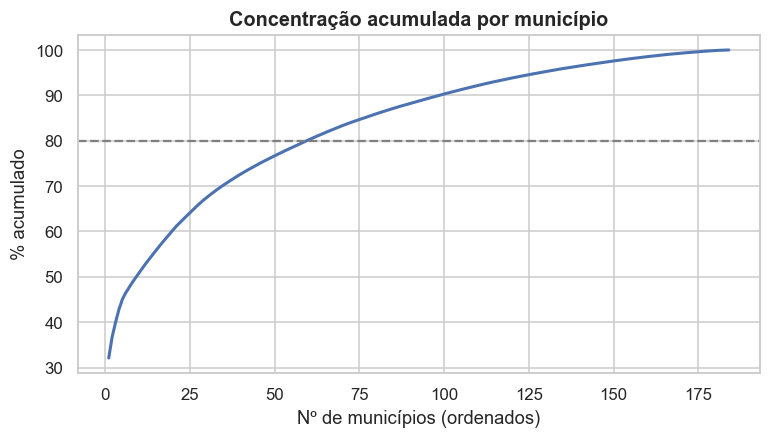

Municípios necessários para 80% dos registros: 60


In [17]:
# Curva de concentração (Pareto) dos municípios
c = df['municipio'].value_counts()
cum = c.cumsum()/c.sum()
plt.figure(figsize=(8,4)); plt.plot(range(1,len(c)+1), cum.values*100, lw=2)
plt.axhline(80, ls='--', c='gray'); plt.title('Concentração acumulada por município'); plt.xlabel('Nº de municípios (ordenados)'); plt.ylabel('% acumulado')
plt.show()
print('Municípios necessários para 80% dos registros:', int((cum<0.8).sum()+1))

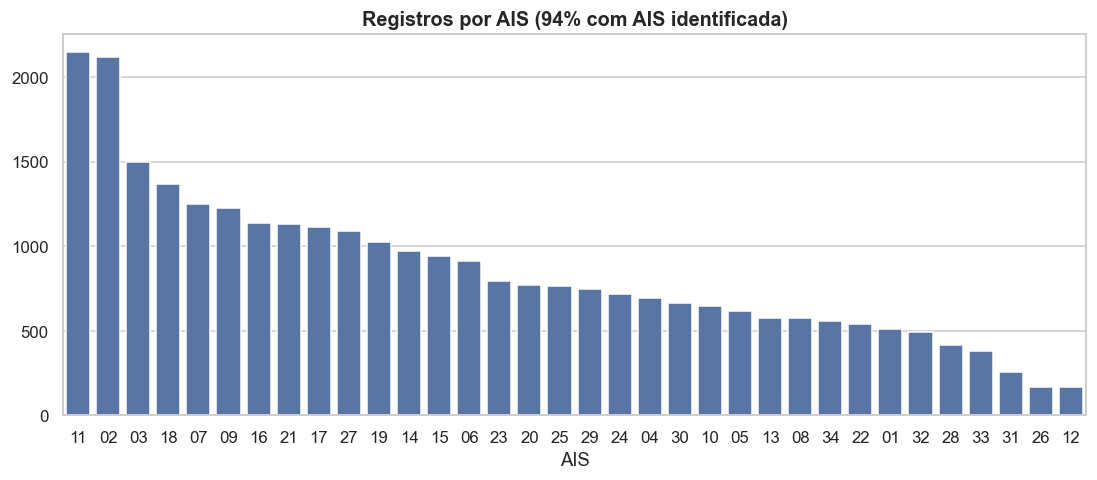

In [18]:
# AIS (Áreas Integradas de Segurança), somente identificadas
ais = df[df['ais_ident']]['ais'].value_counts()
fig, ax = plt.subplots(figsize=(12,4.5))
sns.barplot(x=ais.index.str.replace('AIS ',''), y=ais.values, color='#4C72B0', ax=ax)
ax.set_title(f"Registros por AIS ({df['ais_ident'].mean():.0%} com AIS identificada)"); ax.set_xlabel('AIS')
plt.show()

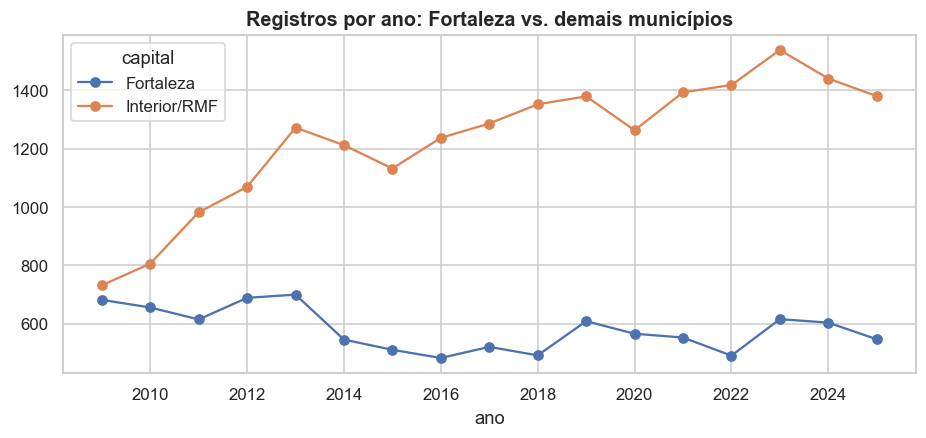

ano           2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  \
capital                                                                    
Fortaleza     48.2  44.9  38.5  39.2  35.5  31.1  31.1  28.1  28.8  26.7   
Interior/RMF  51.8  55.1  61.5  60.8  64.5  68.9  68.9  71.9  71.2  73.3   

ano           2019  2020  2021  2022  2023  2024  2025  
capital                                                 
Fortaleza     30.6  30.9  28.4  25.7  28.6  29.5  28.4  
Interior/RMF  69.4  69.1  71.6  74.3  71.4  70.5  71.6  


In [19]:
# Evolução anual: Fortaleza x resto do estado
pv = df.groupby(['ano','capital']).size().unstack()
ax = pv.plot(figsize=(10,4), marker='o'); ax.set_title('Registros por ano: Fortaleza vs. demais municípios'); plt.show()
print((pv.div(pv.sum(axis=1), axis=0)*100).round(1).T)

> **Limitação:** contagens absolutas favorecem municípios grandes. Para comparar territórios com justiça é preciso a **taxa por 100 mil habitantes**, o que exige juntar dados de população (IBGE/SIDRA). Veja a seção *Próximos passos*.

## 7. Estatística inferencial

### 7.1 Os registros se distribuem uniformemente pelos dias da semana?

In [20]:
obs = df['dia_semana'].value_counts().reindex(ordem_dias).values
chi2, p = stats.chisquare(obs)   # H0: distribuição uniforme
print(f'χ² = {chi2:.1f}, p = {p:.2e}')
print('Cramér-like (efeito):', round(np.sqrt(chi2/ (obs.sum()*(len(obs)-1))),3))

χ² = 170.3, p = 3.83e-34
Cramér-like (efeito): 0.03


### 7.2 Gênero × faixa etária (associação)

In [21]:
tab = pd.crosstab(df_g['genero'], df_g['faixa_etaria'])
chi2, p, dof, _ = stats.chi2_contingency(tab)
n = tab.values.sum(); v = np.sqrt(chi2/(n*(min(tab.shape)-1)))
print(f'χ²({dof}) = {chi2:.1f}, p = {p:.2e}, V de Cramér = {v:.3f}')
# Idade: masculino vs feminino
f = df_g[df_g.genero=='Feminino']['idade'].dropna(); mm = df_g[df_g.genero=='Masculino']['idade'].dropna()
u, p = stats.mannwhitneyu(f, mm)
print(f'Mann-Whitney idade F vs M: p = {p:.2e} | mediana F={f.median():.0f}, M={mm.median():.0f}')

χ²(5) = 713.8, p = 5.13e-152, V de Cramér = 0.155
Mann-Whitney idade F vs M: p = 6.41e-149 | mediana F=12, M=9


### 7.3 A pandemia alterou o nível de registros? (2020–21 vs. 2018–19)

Média mensal pré/pandemia/pós: 160 157 169
Mann-Whitney pré vs pandemia: MannwhitneyuResult(statistic=np.float64(301.0), pvalue=np.float64(0.7965221785356195))
Mann-Whitney pandemia vs pós: MannwhitneyuResult(statistic=np.float64(229.5), pvalue=np.float64(0.23164402674160633))


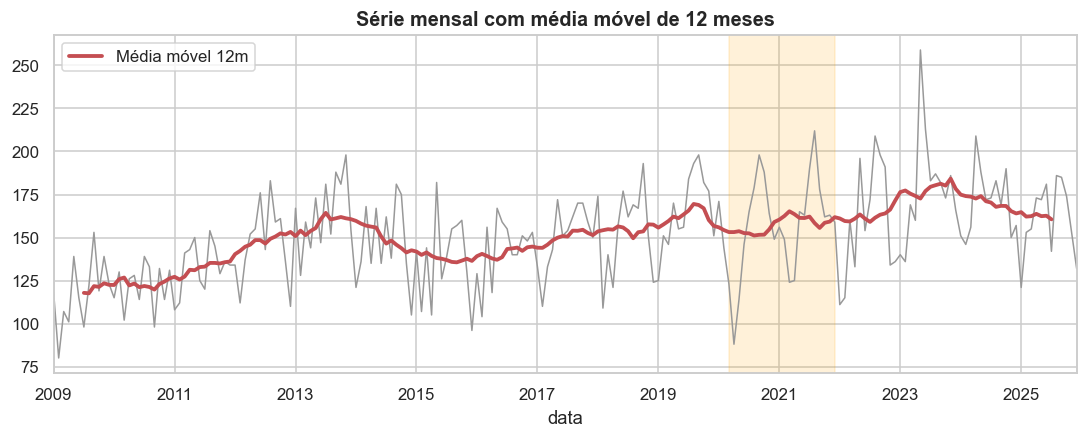

In [22]:
mensal = df.groupby(pd.Grouper(key='data', freq='MS')).size()
pre  = mensal['2018-01':'2019-12']; pand = mensal['2020-01':'2021-12']; pos = mensal['2022-01':'2023-12']
print('Média mensal pré/pandemia/pós:', round(pre.mean()), round(pand.mean()), round(pos.mean()))
print('Mann-Whitney pré vs pandemia:', stats.mannwhitneyu(pre, pand))
print('Mann-Whitney pandemia vs pós:', stats.mannwhitneyu(pand, pos))
fig, ax = plt.subplots(figsize=(12,4))
mensal.plot(ax=ax, lw=1, color='#999'); mensal.rolling(12, center=True).mean().plot(ax=ax, lw=2.5, color='#C44E52', label='Média móvel 12m')
ax.axvspan('2020-03','2021-12', color='orange', alpha=.15); ax.set_title('Série mensal com média móvel de 12 meses'); ax.legend(); plt.show()

### 7.4 Correlação: idade da vítima × ano

Spearman ano×idade: ρ = -0.013, p = 2.78e-02


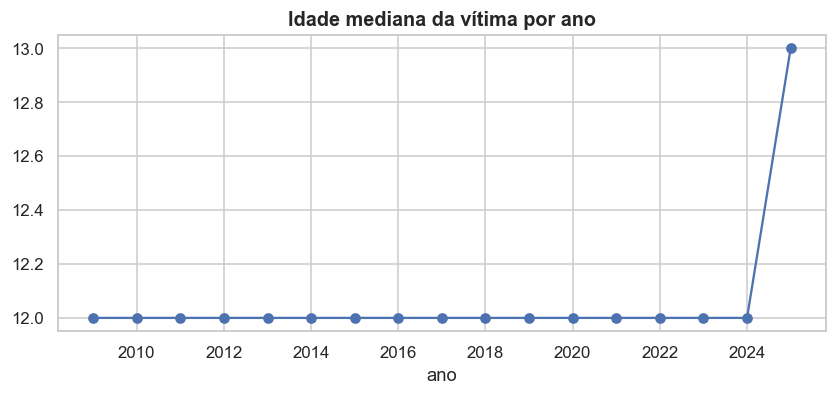

In [23]:
sub = df.dropna(subset=['idade'])
rho, p = stats.spearmanr(sub['ano'], sub['idade'])
print(f'Spearman ano×idade: ρ = {rho:.3f}, p = {p:.2e}')
med = sub.groupby('ano')['idade'].median()
med.plot(marker='o', figsize=(9,3.5), title='Idade mediana da vítima por ano'); plt.show()

### 7.5 Intervalo de confiança para a proporção de vítimas menores de 14 anos (bootstrap)

In [24]:
rng = np.random.default_rng(42)
x = (sub['idade']<14).astype(int).values
boot = [rng.choice(x, len(x)).mean() for _ in range(2000)]
print(f'Proporção <14 anos: {x.mean():.1%}  IC95% bootstrap: [{np.percentile(boot,2.5):.1%}, {np.percentile(boot,97.5):.1%}]')

Proporção <14 anos: 64.4%  IC95% bootstrap: [63.8%, 64.9%]


### 7.6 Sensibilidade: resultados mudam sem as duplicatas exatas?

In [25]:
dd = df.drop_duplicates(subset=['ais','municipio','data','hora','genero','idade','escolaridade','raca'])
print(f'Linhas: {len(df):,} → {len(dd):,}')
print('Mediana idade:', df['idade'].median(), '→', dd['idade'].median())
print('% feminino   :', f"{(df.genero=='Feminino').mean():.1%} → {(dd.genero=='Feminino').mean():.1%}")
print('Pico anual   :', df.groupby('ano').size().idxmax(), '→', dd.groupby('ano').size().idxmax())

Linhas: 30,772 → 30,425
Mediana idade: 12.0 → 12.0
% feminino   : 86.1% → 86.1%
Pico anual   : 2023 → 2023


## 8. Principais conclusões

In [26]:
tot=len(df); tot_fmt=f'{len(df):,}'.replace(',','.'); fem=(df.genero=='Feminino').mean(); menor14=(sub['idade']<14).mean(); fz=(df.municipio=='Fortaleza').mean()
print(f'''
• {tot_fmt} registros em 2009–2025; {fem:.0%} das vítimas são do gênero feminino.
• Idade mediana {df.idade.median():.0f} anos; {menor14:.0%} das vítimas (com idade informada) têm menos de 14 anos.
• Série anual com tendência de alta (Kendall tau={tau:.2f}); pico em {anual.idxmax()}.
• Fortaleza concentra {fz:.0%} dos registros; poucos municípios respondem por ~80% do total.
• Dia da semana não é uniforme (p<0,001), mas o efeito é pequeno; {hc:.0%} dos horários são em hora cheia, indício de horário aproximado.
• Pandemia (2020–21): sem mudança significativa na média mensal vs. 2018–19 (Mann-Whitney, p>0,05).
• Idade da vítima praticamente estável ao longo dos anos (Spearman ρ≈0).
• Raça ({df.raca_ok.isna().mean():.0%} ausente) e escolaridade ({df.escolaridade_ok.isna().mean():.0%} ausente) têm qualidade limitada.
''')


• 30.772 registros em 2009–2025; 86% das vítimas são do gênero feminino.
• Idade mediana 12 anos; 64% das vítimas (com idade informada) têm menos de 14 anos.
• Série anual com tendência de alta (Kendall tau=0.66); pico em 2023.
• Fortaleza concentra 32% dos registros; poucos municípios respondem por ~80% do total.
• Dia da semana não é uniforme (p<0,001), mas o efeito é pequeno; 55% dos horários são em hora cheia, indício de horário aproximado.
• Pandemia (2020–21): sem mudança significativa na média mensal vs. 2018–19 (Mann-Whitney, p>0,05).
• Idade da vítima praticamente estável ao longo dos anos (Spearman ρ≈0).
• Raça (77% ausente) e escolaridade (34% ausente) têm qualidade limitada.



### Limitações
- Registros ≠ incidência (subnotificação; mudanças em políticas de denúncia e tipificação legal ao longo do tempo).
- Sem ID de ocorrência: não é possível separar duplicatas reais de vítimas múltiplas.
- Sem população por município: contagens absolutas, não taxas.

### Próximos passos
1. Juntar população do IBGE e calcular **taxa por 100 mil hab.**; mapa coroplético com `geopandas`.
2. Modelar a série temporal (decomposição STL / SARIMA) e prever 12 meses.
3. Modelo de classificação (ex.: prever faixa etária <14) com `scikit-learn` e análise de importância de variáveis.
4. Dashboard interativo em Power BI com os principais indicadores.